# Auto encoder

An autoencoder is a neural network that learns to compress input data into a lower-dimensional representation and then reconstruct the original data from that representation.

An autoencoder is a neural network that learns to encode high-dimensional data into a lower-dimensional latent representation and decode that representation to reconstruct the original data.

# For more info click the link below 

https://docs.google.com/document/d/1hFDMPaxYYIWVPJjncv-v6TDAug6bdGItNRiRHG1c4jE/edit?usp=sharing

# Notes and interview Question and answer

https://docs.google.com/document/d/1pYanHn2dBUY2-jGiCvEOtmpZlOyXJGqY-VqvqmMOVvo/edit?usp=sharing

# Coding

# Import libraries 

`We will use tensorflow/keras`

In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [5]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization
import tensorflow as tf

from tensorflow.keras.datasets import mnist             # Built-in MNIST handwritten-digit dataset
from tensorflow.keras import Model                       # Create the autoencoder model
from tensorflow.keras import Input                       # Define the model input
from tensorflow.keras.layers import Dense               # Fully connected neural-network layer

# load MNIST

In [6]:
(X_train, _), (X_test, _) = mnist.load_data()            # Load MNIST; labels aren't required for unsupervised training

print("Training shape:", X_train.shape)                 # 60,000 images × 28 × 28 pixels
print("Testing shape:", X_test.shape)                   # 10,000 images × 28 × 28 pixels

Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


# Normalize the images 

`Pixel values range from :`

0-255

`Neural networks generally work better with smaller normalized values . `



In [9]:
X_train = X_train.astype("float32") / 255.0              # Convert pixels to float and scale them to 0–1

X_test = X_test.astype("float32") / 255.0                # Apply the same scaling to test images


# 0 - 0.0
# 255 - 1.0 

# now the images is :- 28*28 

# We need to convert it into:

In [11]:
X_train = X_train.reshape(
    X_train.shape[0],                                    # Keep the number of images unchanged
    784                                                   # Flatten each 28×28 image into 784 features
)

X_test = X_test.reshape(
    X_test.shape[0],                                     # Keep the number of test images unchanged
    784                                                   # Flatten each image into 784 features
)

print("Training shape:", X_train.shape)                 # 60,000 × 784
print("Testing shape:", X_test.shape)                    # 10,000 × 784


# So our problem is now 

# 784 features 

# autoencoder

# compressed representation

Training shape: (60000, 784)
Testing shape: (10000, 784)


# Build the Encoder 

`let's create:`
`784 - 128 - 32`



# Build the encoder 
`let's create = 784 - 128 - 32`

` The 32 neurons will be our latent representation.`

In [ ]:
input_layer = Input(
    shape=(784,)                                        # Each input sample contains 784 pixel features
)

encoder_layer = Dense(
    128,
    activation="relu"                                    # Learn a nonlinear representation with 128 neurons
)(input_layer)

latent_layer = Dense(
    32,
    activation="relu"                                    # Compress 784 features into a 32-dimensional representation
)(encoder_layer)

#So = 784 - 128 - 32
# The bottleneck is - 32

# Build the decoder 

`Now we need to reconstruct the original 784 pixels.`

In [15]:
decoder_layer = Dense(
    128,
    activation="relu"                                    # Expand the 32-dimensional representation back toward the original size
)(latent_layer)

output_layer = Dense(
    784,
    activation="sigmoid"                                 # Produce 784 reconstructed pixel values between 0 and 1
)(decoder_layer)


# 84
# ↓
# 128
# ↓
# 32   ← Bottleneck / latent representation
# ↓
# 128
# ↓
# 784

# Create autoencoder 

In [16]:
autoencoder = Model(
    input_layer,                                         # Input of the network
    output_layer                                         # Reconstructed output
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

# Compile the model 

In [ ]:
autoencoder.compile(
    optimizer="adam",                                    # Adam updates the network weights during training
    loss="binary_crossentropy"                            # Measures difference between original and reconstructed pixels
)

# Why binary cross-entropy ? 
# Because our pixel values have been normalized to: -   0-1 
# And the output layer uses:

# activation="sigmoid" 

# Train the Autoencoder 
`This is the important part.`

In [18]:
history = autoencoder.fit(
    X_train,                                              # Original images are the input
    X_train,                                              # The same images are the reconstruction targets
    epochs=20,                                            # Train the network for 20 complete passes through the data
    batch_size=256,                                      # Process 256 images before updating the weights
    validation_data=(X_test, X_test),                    # Evaluate reconstruction performance on unseen images
    shuffle=True                                          # Randomize training samples between epochs
)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.1526 - val_loss: 1.5475e-04
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6.7230e-05 - val_loss: 3.7851e-05
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 3.2586e-05 - val_loss: 3.0184e-05
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.8899e-05 - val_loss: 2.8608e-05
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.7949e-05 - val_loss: 2.8051e-05
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.7547e-05 - val_loss: 2.7758e-05
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.7315e-05 - val_loss: 2.7570e-05
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.7162e-05 - val_loss: 2.7441e-05
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.7056e-05 - val_loss: 2.7351e-05
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.6981e-05 - val_loss: 2.7286e-05
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.

# Plot training loss

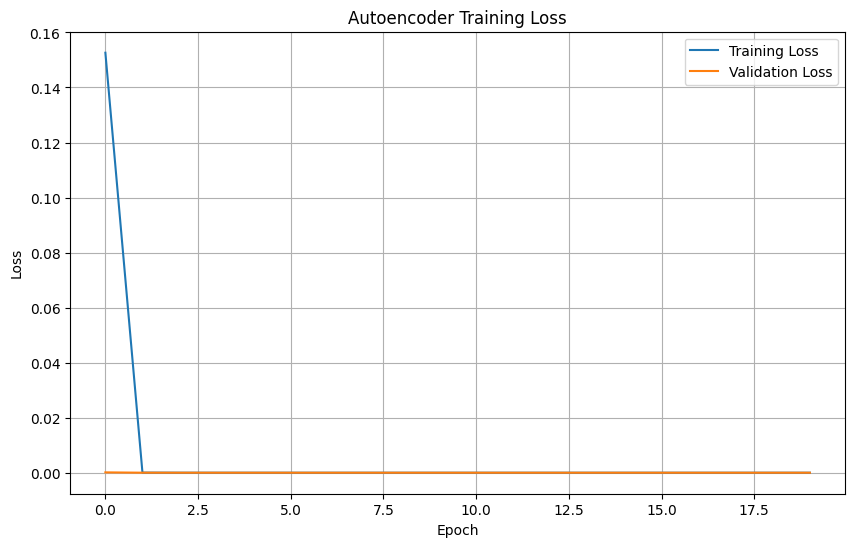

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],                             # Training reconstruction loss
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],                         # Validation reconstruction loss
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Loss")

plt.legend()
plt.grid()
plt.show()

# Create the encoder separately 
`The full autoencoder gives us:`
`Input → compressed → reconstructed output`

`But we want the compressed representation.`

`So we create a separate encoder:`

In [21]:
encoder = Model(
    input_layer,                                         # Start from the original 784-dimensional input
    latent_layer                                         # Stop at the 32-dimensional bottleneck
)

In [23]:
X_train_encoded = encoder.predict(
    X_train                                             # Convert every training image into its 32-dimensional representation
)

X_test_encoded = encoder.predict(
    X_test                                              # Convert test images into their 32-dimensional representation
)

print("Original shape:", X_train.shape)                # 60,000 × 784
print("Encoded shape:", X_train_encoded.shape)         # 60,000 × 32

# We have achived simensionality reduction : 

# 784 dimensions - autoencoder - 32 dimensions. 

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 386us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 298us/step
Original shape: (60000, 784)
Encoded shape: (60000, 32)


`Reconstruct some images `
`Now let's see whether the decoder can reconstruct the compressed information `

In [24]:
decoded_images = autoencoder.predict(
    X_test[:10]                                         # Reconstruct the first 10 test images
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


# Compare the original vs recostructed images 


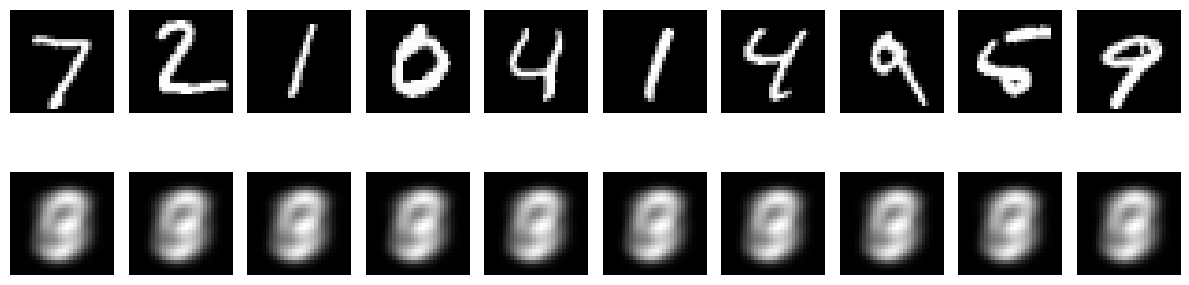

In [25]:
plt.figure(figsize=(12, 4))

for i in range(10):

    # Original image
    ax = plt.subplot(2, 10, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),                      # Convert 784 features back into a 28×28 image
        cmap="gray"
    )

    plt.axis("off")


    # Reconstructed image
    ax = plt.subplot(2, 10, i + 11)

    plt.imshow(
        decoded_images[i].reshape(28, 28),              # Convert reconstructed 784 pixels back into 28×28
        cmap="gray"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

`It means my auto encoder has not learned a good representation of the images yet.`

Original 7 → compressed → reconstructed 7
Original 2 → compressed → reconstructed 2
Original 1 → compressed → reconstructed 1
Original 0 → compressed → reconstructed 0
...

7 → compressed → "same blurry shape"
2 → compressed → "same blurry shape"
1 → compressed → "same blurry shape"
0 → compressed → "same blurry shape"
...

So the decoder is producing nearly the same average-looking image for many different inputs.

`What is this happening ? `

Most likely the model hasn't learned enough useful information in its talent. representation .


i currently have 

784
 ↓
128
 ↓
32
 ↓
128
 ↓
784

The 32-dimensional bottleneck is forcing compression, but the model should still be able to reconstruct MNIST much better than this.

possible causes include 

insufficient training 
epochs=20 
The bottleneck may be too restrictive 
try with 64 instead of 32. 

 Maybe architecture too simple


784
 ↓
256
 ↓
128
 ↓
64
 ↓
128
 ↓
256
 ↓
784


Most importantly, check your training loss.

If your loss is not decreasing properly, the network isn't learning the reconstruction task.


One important thing

This output is not what we want.

A good autoencoder output should look more like:


Original:        7   2   1   0   4

Reconstructed:   7   2   1   0   4



# Visualize the 32 dimensional representation 
`We can't directly plot 32 dimensions.`

`But we can use PCA only for Visualization:`

In [28]:
# 784
# ↓
# Autoencoder
# ↓
# 32
# ↓
# PCA
# ↓
# 2

# However, remember that is not a part of the autoencoder itself.  

from sklearn.decomposition import PCA                    # PCA is used only to visualize the 32D latent space

pca = PCA(
    n_components=2                                       # Reduce the 32D latent representation to 2D for plotting
)

latent_2d = pca.fit_transform(
    X_test_encoded                                      # Visualize the learned latent representations
)

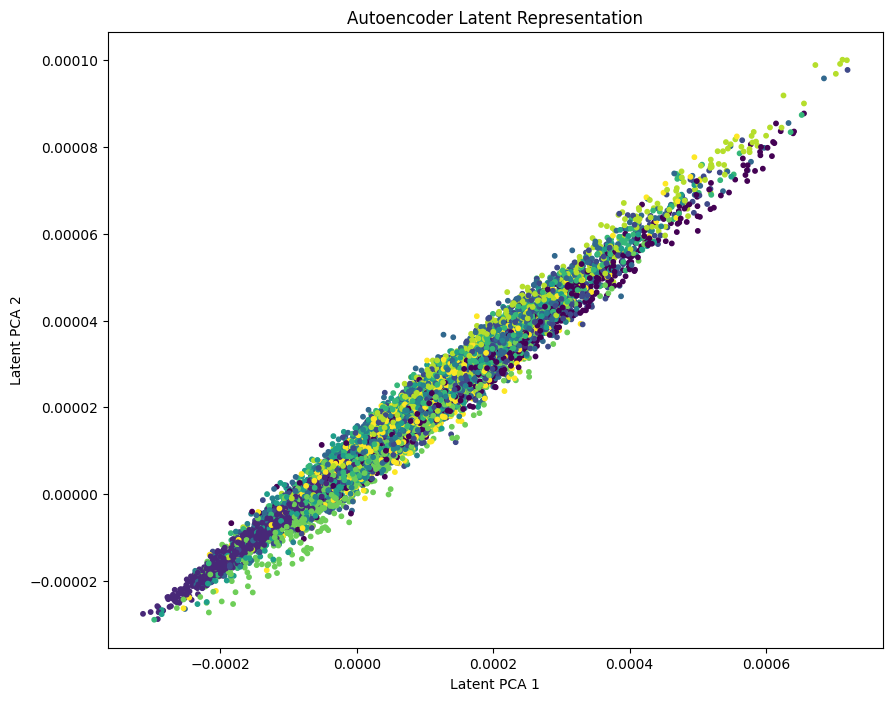

In [29]:
# Then 

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    latent_2d[:, 0],                                    # First PCA dimension of the latent representation
    latent_2d[:, 1],                                    # Second PCA dimension of the latent representation
    c=_,                                                 # We intentionally don't have labels available here
    s=10
)

plt.xlabel("Latent PCA 1")
plt.ylabel("Latent PCA 2")
plt.title("Autoencoder Latent Representation")

plt.show()

# Complete full code 

In [30]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from tensorflow.keras.datasets import mnist             # Built-in MNIST dataset
from tensorflow.keras import Model                       # Build neural-network models
from tensorflow.keras import Input                       # Define input shape
from tensorflow.keras.layers import Dense               # Fully connected neural-network layer


(X_train, _), (X_test, _) = mnist.load_data()            # Load images; labels aren't needed for training


X_train = X_train.astype("float32") / 255.0              # Normalize training pixels to 0–1
X_test = X_test.astype("float32") / 255.0                # Normalize test pixels to 0–1


X_train = X_train.reshape(
    X_train.shape[0],
    784                                                   # Flatten 28×28 images into 784 features
)

X_test = X_test.reshape(
    X_test.shape[0],
    784                                                   # Flatten test images into 784 features
)


input_layer = Input(
    shape=(784,)                                         # Autoencoder receives 784 pixel features
)


encoder_layer = Dense(
    128,
    activation="relu"                                    # Learn a nonlinear intermediate representation
)(input_layer)


latent_layer = Dense(
    32,
    activation="relu"                                    # Compress 784 features into 32 latent features
)(encoder_layer)


decoder_layer = Dense(
    128,
    activation="relu"                                    # Expand the latent representation
)(latent_layer)


output_layer = Dense(
    784,
    activation="sigmoid"                                 # Reconstruct 784 normalized pixel values
)(decoder_layer)


autoencoder = Model(
    input_layer,
    output_layer                                         # Complete encoder + decoder model
)


autoencoder.compile(
    optimizer="adam",                                    # Optimize neural-network weights
    loss="binary_crossentropy"                            # Measure reconstruction error
)


history = autoencoder.fit(
    X_train,                                              # Original images are inputs
    X_train,                                              # Same images are reconstruction targets
    epochs=20,                                            # Number of training passes
    batch_size=256,                                      # Images processed before each weight update
    validation_data=(X_test, X_test),                    # Evaluate reconstruction on unseen images
    shuffle=True                                          # Shuffle training examples
)


encoder = Model(
    input_layer,
    latent_layer                                         # Extract only the compressed representation
)


X_encoded = encoder.predict(
    X_test                                               # Convert test images from 784D to 32D
)


print("Original shape:", X_test.shape)                   # 10,000 × 784
print("Encoded shape:", X_encoded.shape)                # 10,000 × 32

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2290 - val_loss: 0.1504
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1347 - val_loss: 0.1202
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1157 - val_loss: 0.1093
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1081 - val_loss: 0.1039
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1037 - val_loss: 0.1010
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1008 - val_loss: 0.0985
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0986 - val_loss: 0.0964
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0970 - val_loss: 0.0950
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0957 - val_loss: 0.0938
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0945 - val_loss: 0.0926
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0936 - val_loss: 0.0918
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step